#### Fashion MNIST
: 옷과 신발 및 가방의 이미지를 10개의 클래스로 분류

- train set : 60000
- test set : 10000
- image : 28x28(흑백이미지)
- class

| index | 분류 |
| --- | --- |
| 0 | T-shirt/top | 
| 1 | Trouser |
| 2 | Pullover |
| 3 | Dress |
| 4 | Coat |
| 5 | Sandal |
| 6 | Shirt |
| 7 | Sneaker |
| 8 | Bag |
| 9 | Ankle boot |

In [2]:
from multiclass_functions import *
import torch
from torch import nn, optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import numpy as np
import matplotlib.pyplot as plt
import os
os.makedirs('results', exist_ok=True)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(DEVICE)

cpu


In [3]:
BATCH_SIZE = 32
LR = 1e-3
EPOCH = 5
criterion = nn.CrossEntropyLoss()
new_model_train = True
model_type = 'CNN'
dataset = 'FashionMNIST'
save_model_path = f'results/{model_type}_{dataset}.pt'

In [4]:
transform = transforms.ToTensor()
train_DS = datasets.FashionMNIST(root='data', train=True, download=True, transform=transform)
test_DS = datasets.FashionMNIST(root='data', train=False, download=True, transform=transform)
train_DL = DataLoader(train_DS, batch_size=BATCH_SIZE, shuffle=True)
test_DL = DataLoader(test_DS, batch_size=BATCH_SIZE, shuffle=True)

100%|██████████| 26.4M/26.4M [00:13<00:00, 1.95MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 107kB/s]
100%|██████████| 4.42M/4.42M [00:02<00:00, 1.71MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 5.17MB/s]


['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
{'T-shirt/top': 0, 'Trouser': 1, 'Pullover': 2, 'Dress': 3, 'Coat': 4, 'Sandal': 5, 'Shirt': 6, 'Sneaker': 7, 'Bag': 8, 'Ankle boot': 9}
torch.Size([32, 1, 28, 28])
T-shirt/top


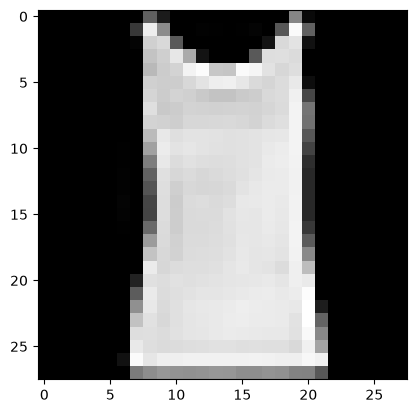

In [22]:
print(test_DS.classes)
print(test_DS.class_to_idx)

x_batch, y_batch = next(iter(train_DL))
print(x_batch.shape)

plt.imshow(x_batch[0,0], cmap='gray')
print(test_DS.classes[y_batch[0]])

In [24]:
class CNN(nn.Module):
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.conv1 = nn.Sequential(nn.Conv2d(1,8,3, padding=1),
                                   nn.BatchNorm2d(8),
                                   nn.ReLU()
                                   )
        self.Maxpool1 = nn.MaxPool2d(2)
        self.conv2 = nn.Sequential(nn.Conv2d(8,16,3, padding=1),
                                   nn.BatchNorm2d(16),
                                   nn.ReLU()
                                   )
        self.Maxpool2 = nn.MaxPool2d(2)
        self.conv3 = nn.Sequential(nn.Conv2d(16,32,3, padding=1),
                                           nn.BatchNorm2d(32),
                                           nn.ReLU()
                                           )
        self.Maxpool3 = nn.MaxPool2d(2)
        self.fc = nn.Linear(32*3*3, 10)

    def forward(self, x):
        x = self.conv1(x)
        x = self.Maxpool1(x)
        x = self.conv2(x)
        x = self.Maxpool2(x)
        x = self.conv3(x)
        x = self.Maxpool3(x)
        x = torch.flatten(x, start_dim=1)
        x = self.fc(x)
        return x

class CNN_deep(nn.Module):
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.conv_block1 = nn.Sequential(nn.Conv2d(1,32,3,padding=1),
                                         nn.BatchNorm2d(32),
                                         nn.ReLU(),
                                         nn.Conv2d(32,32,3,padding=1),
                                         nn.BatchNorm2d(32),
                                         nn.ReLU())
        self.Maxpool1 = nn.MaxPool2d(2)

        self.conv_block2 = nn.Sequential(nn.Conv2d(32,64,3,padding=1),
                                         nn.BatchNorm2d(64),
                                         nn.ReLU(),
                                         nn.Conv2d(64,64,3,padding=1),
                                         nn.BatchNorm2d(64),
                                         nn.ReLU(),
                                         nn.Conv2d(64,64,3,padding=1),
                                         nn.BatchNorm2d(64),
                                         nn.ReLU())
        self.Maxpool2 = nn.MaxPool2d(2)

        self.conv_block3 = nn.Sequential(nn.Conv2d(64,128,3,padding=1),
                                        nn.BatchNorm2d(128),
                                        nn.ReLU(),
                                        nn.Conv2d(128,128,3,padding=1),
                                        nn.BatchNorm2d(128),
                                        nn.ReLU(),
                                        nn.Conv2d(128,128,3,padding=1),
                                        nn.BatchNorm2d(128),
                                        nn.ReLU())
        self.Maxpool3 = nn.MaxPool2d(2)

        self.classifier = nn.Sequential(nn.Linear(128*3*3, 512),
                                        nn.ReLU(),
                                        nn.Linear(512, 10))

    def forward(self, x):
        x = self.conv_block1(x)
        x = self.Maxpool1(x)
        x = self.conv_block2(x)
        x = self.Maxpool2(x)
        x = self.conv_block3(x)
        x = self.Maxpool3(x)
        x = torch.flatten(x, start_dim=1)
        x = self.classifier(x)
        return x

In [25]:
model = globals()[model_type]().to(DEVICE)
print(model)

x_batch, _ = next(iter(train_DL))
print(x_batch.shape)

model.eval()
with torch.no_grad():
    print(model(x_batch.to(DEVICE)).shape)

CNN(
  (conv1): Sequential(
    (0): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(8, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
  )
  (Maxpool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Sequential(
    (0): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
  )
  (Maxpool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Sequential(
    (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
  )
  (Maxpool3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc): Linear(in_features=288, out_features=10, bias=True)
)
torch.Size([32, 

Epoch : 1, train loss : 0.432
--------------------
Epoch : 2, train loss : 0.308
--------------------
Epoch : 3, train loss : 0.277
--------------------
Epoch : 4, train loss : 0.259
--------------------
Epoch : 5, train loss : 0.244
--------------------


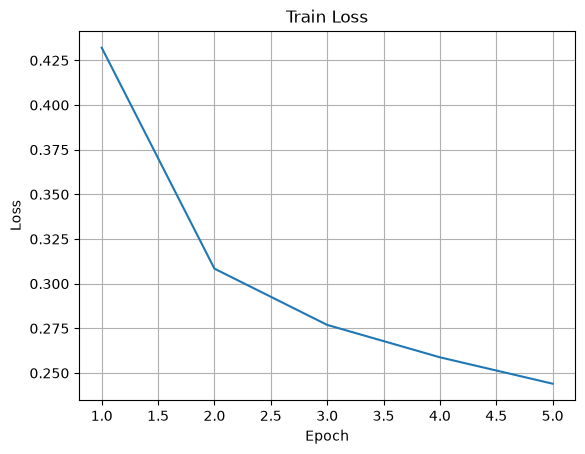

In [26]:
if new_model_train:
    optimizer = optim.Adam(model.parameters(), lr=LR)
    loss_history = Train(model, train_DL, criterion, optimizer, EPOCH)

    torch.save(model, save_model_path)

    plt.figure()
    plt.plot(range(1, EPOCH+1), loss_history)
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title('Train Loss')
    plt.grid()

In [27]:
load_model = torch.load(save_model_path, map_location=DEVICE, weights_only=False)

In [28]:
Test(load_model, test_DL)

Test accuracy : 8915 / 10000 (89.1 %)


89.1

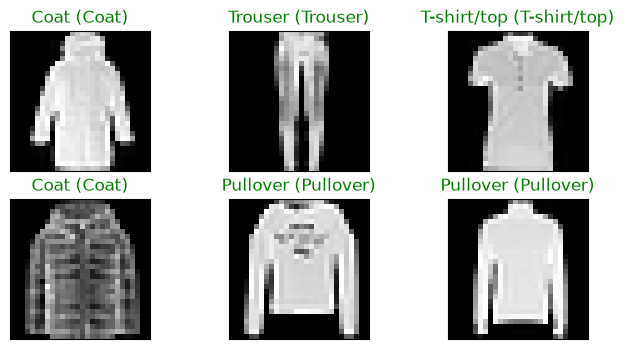

In [29]:
Test_plot(load_model, test_DL)

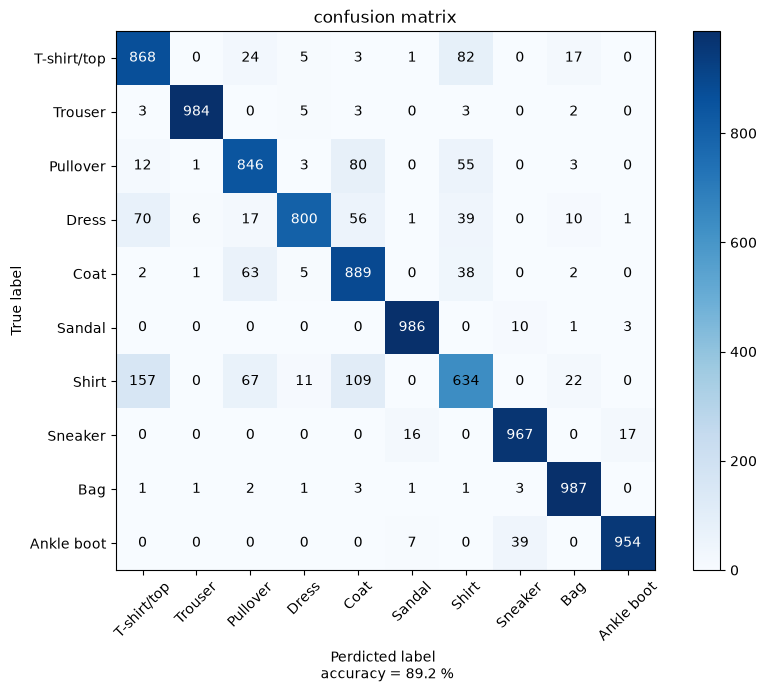

In [31]:
confusion = get_conf(load_model, test_DL)
plot_confusion_matrix(confusion, test_DS.classes)
plt.xticks(rotation=45);

torch.Size([32, 8, 28, 28])
torch.Size([32, 16, 14, 14])
torch.Size([32, 32, 7, 7])


Text(0.5, 1.0, 'Ankle boot (Ankle boot)')

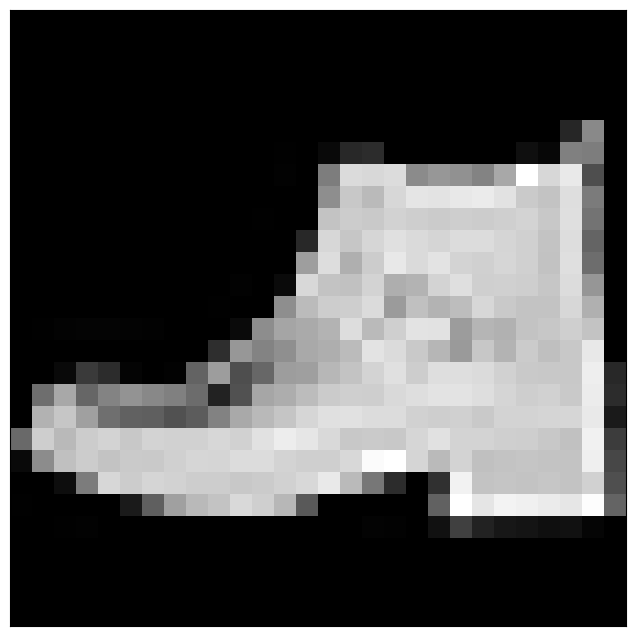

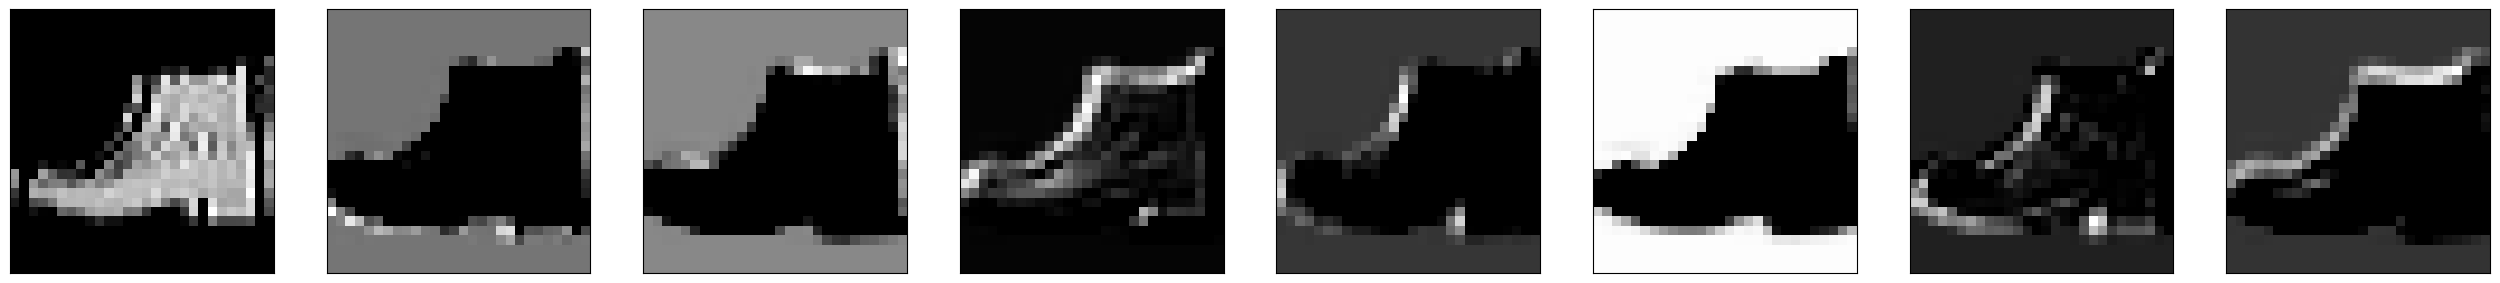

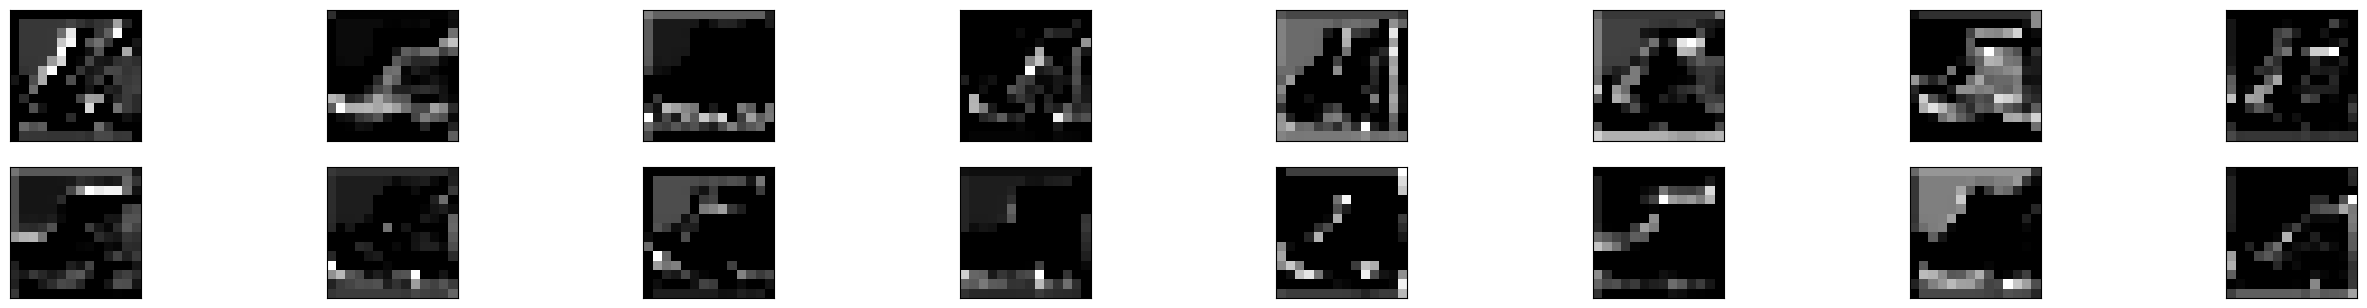

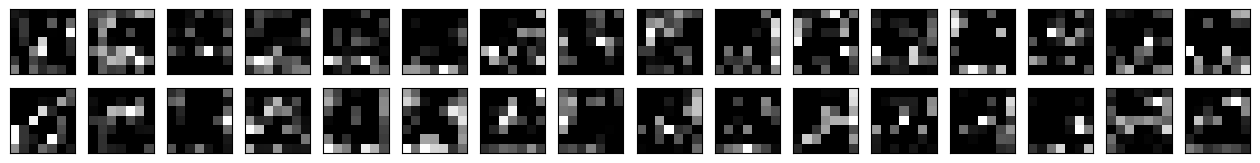

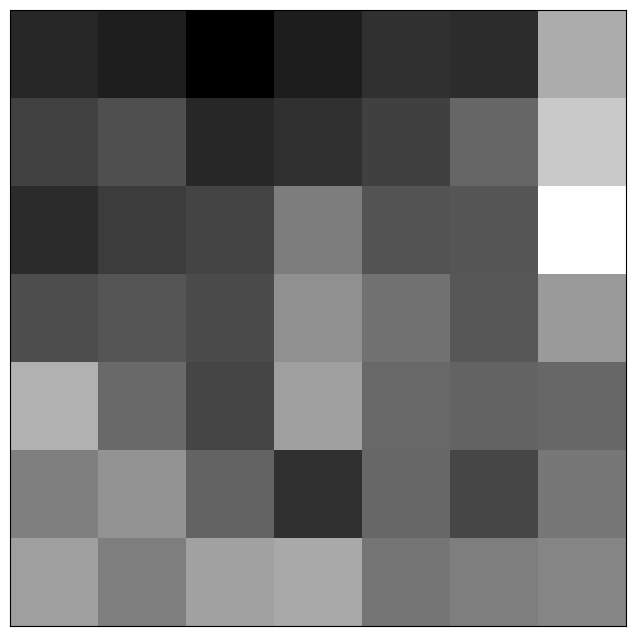

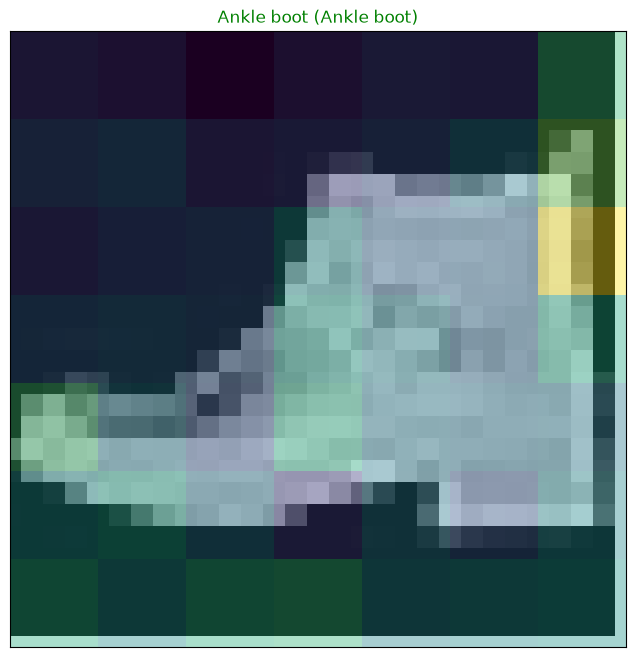

In [32]:
load_model.eval()
with torch.no_grad():
    x_batch, y_batch = next(iter(test_DL))
    x_batch = x_batch.to(DEVICE)
    y_batch = y_batch.to(DEVICE)
    y_hat = load_model(x_batch)
    pred = y_hat.argmax(dim=1)

    # CNN 할 때 사용
    feature_map1 = load_model.conv1(x_batch)
    feature_map2 = load_model.conv2(load_model.Maxpool1(feature_map1))
    feature_map3 = load_model.conv3(load_model.Maxpool2(feature_map2))

    # CNN_deep 할 때 사용
    # feature_map1 = load_model.conv_block1(x_batch)
    # feature_map2 = load_model.conv_block2(load_model.Maxpool1(feature_map1))
    # feature_map3 = load_model.conv_block3(load_model.Maxpool2(feature_map2))

x_batch = x_batch.cpu()
feature_map1 = feature_map1.cpu()
feature_map2 = feature_map2.cpu()
feature_map3 = feature_map3.cpu()

plt.figure(figsize=(8,8))
plt.xticks([])
plt.yticks([])
plt.imshow(x_batch[0,0], cmap='gray')

print(feature_map1.shape)
plt.figure(figsize=(32,16))
for idx in range(feature_map1.shape[1]):
    plt.subplot(4,8, idx+1, xticks=[], yticks=[])
    plt.imshow(feature_map1[0,idx], cmap='gray')

print(feature_map2.shape)
plt.figure(figsize=(32,16))
for idx in range(feature_map2.shape[1]):
    plt.subplot(8,8, idx+1, xticks=[], yticks=[])
    plt.imshow(feature_map2[0,idx], cmap='gray')

print(feature_map3.shape)
plt.figure(figsize=(16,8))
for idx in range(feature_map3.shape[1]):
    plt.subplot(8,16, idx+1, xticks=[], yticks=[])
    plt.imshow(feature_map3[0,idx], cmap='gray')

summed_map = feature_map3.sum(dim=1)
plt.figure(figsize=(8,8))
plt.xticks([])
plt.yticks([])
plt.imshow(summed_map[0], cmap='gray')

plt.figure(figsize=(8,8))
plt.xticks([])
plt.yticks([])
plt.imshow(x_batch[0,0], cmap='gray')
plt.imshow(summed_map[0], extent=[0,28,28,0], alpha=0.4, cmap='viridis')
pred_item = test_DS.classes[pred[0].item()]
true_item = test_DS.classes[y_batch[0].item()]
plt.title(f'{pred_item} ({true_item})', color='g' if pred_item == true_item else 'r')

torch.Size([1, 8, 28, 28])
torch.Size([1, 16, 14, 14])
torch.Size([1, 32, 7, 7])


Text(0.5, 1.0, 'Shirt (Pullover)')

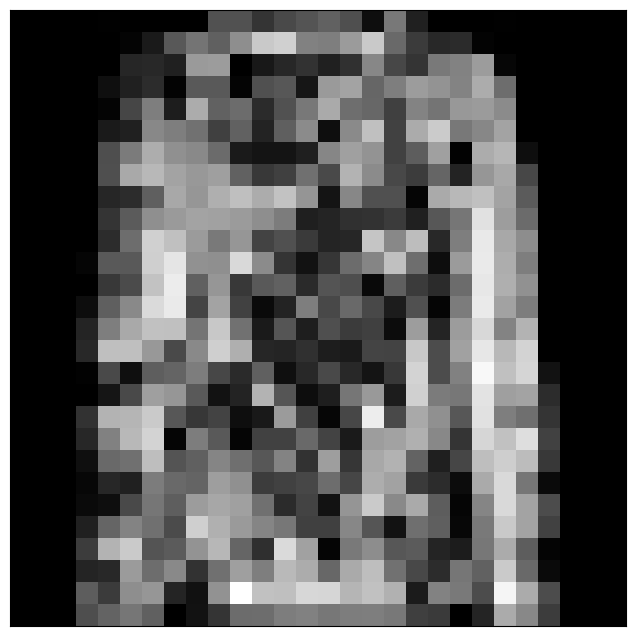

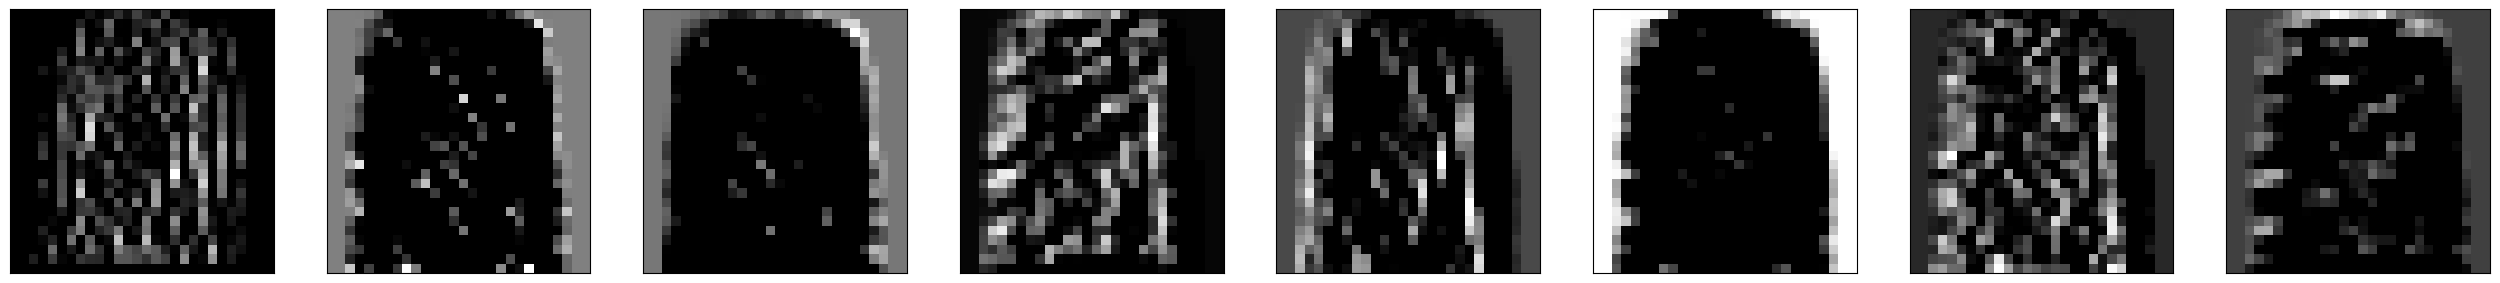

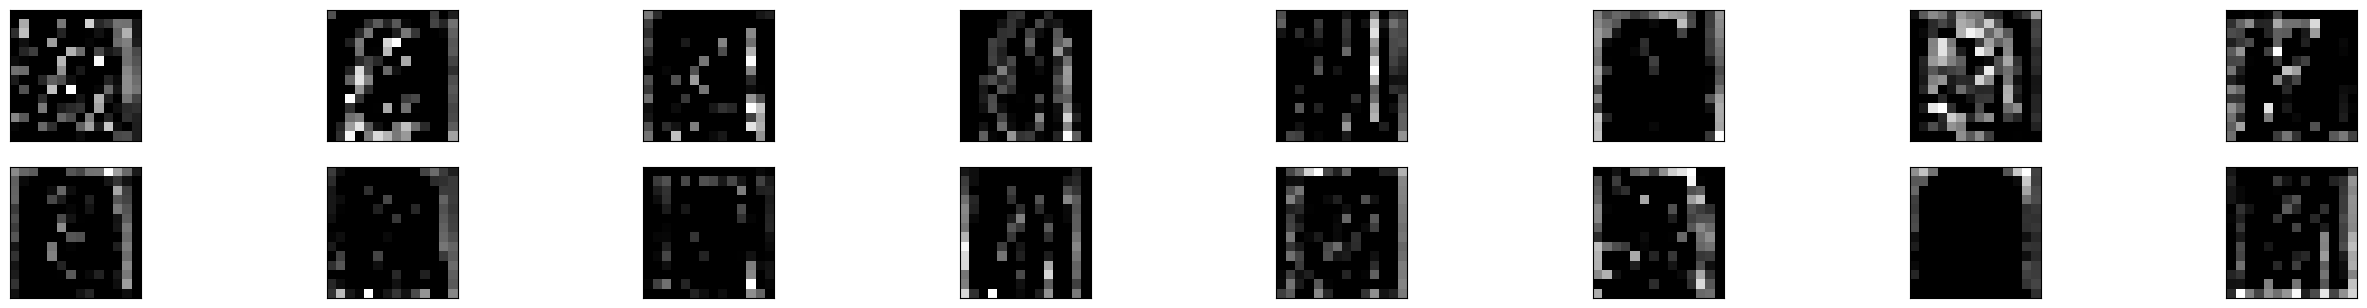

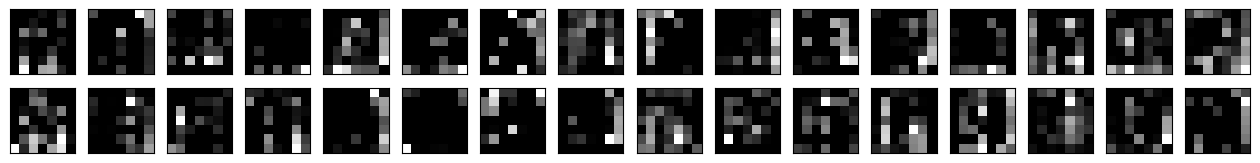

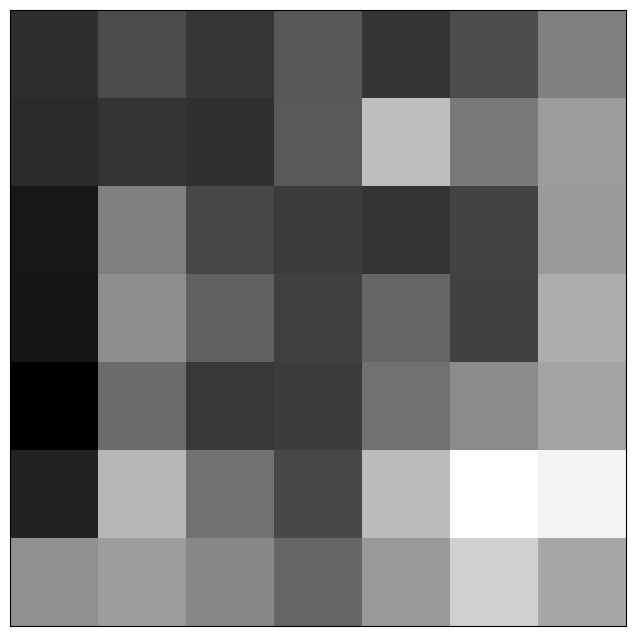

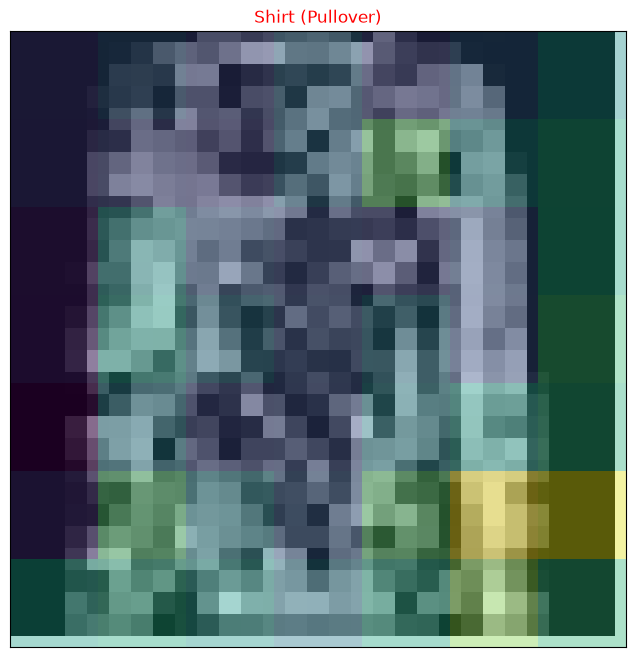

In [34]:
load_model.eval()
with torch.no_grad():
    wrong_image = None

    for x_batch, y_batch in test_DL:
        x_batch, y_batch = next(iter(test_DL))
        x_batch = x_batch.to(DEVICE)
        y_batch = y_batch.to(DEVICE)
        y_hat = load_model(x_batch)
        pred = y_hat.argmax(dim=1)

        wrong_idx = torch.where(pred != y_batch)[0]

        if len(wrong_idx) > 0 :
            idx = wrong_idx[0].item()

            wrong_image = x_batch[idx:idx+1]

            pred_label = pred[idx].item()
            true_label = y_batch[idx].item()

    if wrong_image is not None :

        # CNN 할 때 사용
        feature_map1 = load_model.conv1(wrong_image)
        feature_map2 = load_model.conv2(load_model.Maxpool1(feature_map1))
        feature_map3 = load_model.conv3(load_model.Maxpool2(feature_map2))

        # CNN_deep 할 때 사용
        # feature_map1 = load_model.conv_block1(wrong_image)
        # feature_map2 = load_model.conv_block2(load_model.Maxpool1(feature_map1))
        # feature_map3 = load_model.conv_block3(load_model.Maxpool2(feature_map2))

wrong_image = wrong_image.cpu()
feature_map1 = feature_map1.cpu()
feature_map2 = feature_map2.cpu()
feature_map3 = feature_map3.cpu()

plt.figure(figsize=(8,8))
plt.xticks([])
plt.yticks([])
plt.imshow(wrong_image[0,0], cmap='gray')

print(feature_map1.shape)
plt.figure(figsize=(32,16))
for idx in range(feature_map1.shape[1]):
    plt.subplot(4,8, idx+1, xticks=[], yticks=[])
    plt.imshow(feature_map1[0,idx], cmap='gray')

print(feature_map2.shape)
plt.figure(figsize=(32,16))
for idx in range(feature_map2.shape[1]):
    plt.subplot(8,8, idx+1, xticks=[], yticks=[])
    plt.imshow(feature_map2[0,idx], cmap='gray')

print(feature_map3.shape)
plt.figure(figsize=(16,8))
for idx in range(feature_map3.shape[1]):
    plt.subplot(8,16, idx+1, xticks=[], yticks=[])
    plt.imshow(feature_map3[0,idx], cmap='gray')

summed_map = feature_map3.sum(dim=1)
plt.figure(figsize=(8,8))
plt.xticks([])
plt.yticks([])
plt.imshow(summed_map[0], cmap='gray')

plt.figure(figsize=(8,8))
plt.xticks([])
plt.yticks([])
plt.imshow(wrong_image[0,0], cmap='gray')
plt.imshow(summed_map[0], extent=[0,28,28,0], alpha=0.4, cmap='viridis')
pred_item = test_DS.classes[pred_label]
true_item = test_DS.classes[true_label]
plt.title(f'{pred_item} ({true_item})', color='g' if pred_item == true_item else 'r')